# Supplementary Figure S13c. Conservation of AD loci by colocalization class (secondary meta-analysis)

Locus-level Zoonomia **primate PhastCons** score (range 0-1) for AD fine-mapped credible sets with no colocalization (AD-only, n = 59) and for colocalization CoS of the secondary AD analysis (130 CoS) classed as AD-*cis* (n = 24), AD-*trans* (n = 24) or AD-*cis*-*trans* (n = 82). Each credible set / CoS is one unit and its score is the mean PhastCons over its scored variants. Violins show the density, boxes the interquartile range, white diamonds the median. All six pairs are compared with two-sided Wilcoxon rank-sum tests (normal approximation) and P values are BH-adjusted across the six pairs; brackets/asterisks here use the BH FDR (* FDR < 5%, ** FDR < 1%), as stated in the caption.

Caveats: (1) the author's figure code drew the asterisks from the **uncorrected** P values (V1 panel: AD-only vs AD-*trans* "*", P = 0.047, FDR = 0.14; AD-*trans* vs AD-*cis*-*trans* "**", P = 0.0032, FDR = 0.019); with FDR only AD-*trans* vs AD-*cis*-*trans* remains significant (*). (2) The caption describes phyloP of the lead variant (highest MaxVCP / MaxPIP), but the code that produced this panel uses the mean primate PhastCons over all CoS variants; no lead-variant phyloP version of this panel was found. Both P values are kept in the rds.

Input: `data/Figure_S13c_conservation_phastcons.rds` (list: `scores`, `tests`).

In [1]:
suppressPackageStartupMessages(library(ggplot2))
x <- readRDS("data/Figure_S13c_conservation_phastcons.rds")
cons <- x$scores
tests <- x$tests
head(cons)
table(cons$category)
tests

,unit_id,category,n_variants,n_scored,phastcons_mean
,<chr>,<fct>,<int>,<int>,<dbl>
1,AD_only_chr10_cs4,AD-only,12,12,0.0467500
2,AD_only_chr10_cs6,AD-only,25,25,0.1713200
3,AD_only_chr11_cs7,AD-only,1,1,0.0020000
4,AD_only_chr11_cs8,AD-only,9,9,0.1174444
5,AD_only_chr14_cs14,AD-only,162,162,0.0582963
6,AD_only_chr14_cs16,AD-only,5,5,0.1550000



     AD-only       AD-cis     AD-trans AD-cis-trans 
          59           24           24           82 

group1,group2,n1,n2,median1,median2,p_value,p_adj_BH,star_FDR,star_author_uncorrected
<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
AD-only,AD-cis,59,24,0.05829630,0.01750000,0.50082855,0.5008286,,
AD-only,AD-trans,59,24,0.05829630,0.01358333,0.04721083,0.1416325,,*
AD-only,AD-cis-trans,59,82,0.05829630,0.09914643,0.36327661,0.4359319,,
AD-cis,AD-trans,24,24,0.01750000,0.01358333,0.28788277,0.4318241,,
AD-cis,AD-cis-trans,24,82,0.01750000,0.09914643,0.19275743,0.3855149,,
AD-trans,AD-cis-trans,24,82,0.01358333,0.09914643,0.00315425,0.0189255,*,**


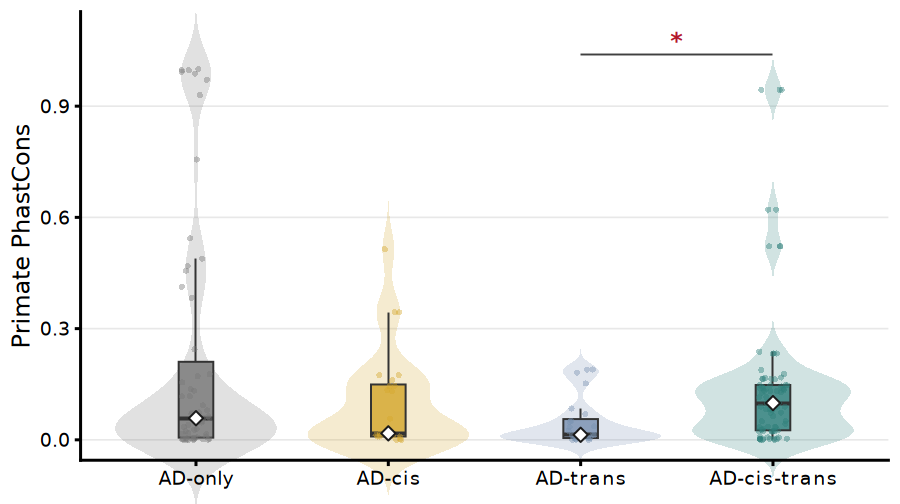

In [2]:
levs <- levels(cons$category)
ymax <- max(cons$phastcons_mean)
step <- ymax * 0.10
sig_pairs <- subset(tests, p_adj_BH < 0.05)
sig_pairs$x1 <- match(sig_pairs$group1, levs)
sig_pairs$x2 <- match(sig_pairs$group2, levs)
sig_pairs <- sig_pairs[order(abs(sig_pairs$x2 - sig_pairs$x1), sig_pairs$x1), ]
sig_pairs$y <- ymax * 1.04 + step * (seq_len(nrow(sig_pairs)) - 1)

cat_colors <- c("AD-only" = "#777777", "AD-cis" = "#D4A72C", "AD-trans" = "#7991B1", "AD-cis-trans" = "#2F7F7B")
cat_labels <- c("AD-only" = "'AD-only'", "AD-cis" = "'AD-'*italic(cis)", "AD-trans" = "'AD-'*italic(trans)",
                "AD-cis-trans" = "'AD-'*italic(cis)*'-'*italic(trans)")
p <- ggplot(cons, aes(category, phastcons_mean, fill = category)) +
  geom_violin(scale = "width", trim = FALSE, alpha = 0.22, color = NA, width = 0.84) +
  geom_boxplot(width = 0.18, outlier.shape = NA, alpha = 0.82, linewidth = 0.42, color = "grey20") +
  geom_point(aes(color = category), position = position_jitter(width = 0.075, height = 0, seed = 2026),
             size = 1.45, alpha = 0.42, stroke = 0) +
  stat_summary(fun = median, geom = "point", shape = 23, size = 2.8, fill = "white", color = "grey10") +
  geom_segment(data = sig_pairs, aes(x = x1, xend = x2, y = y, yend = y), inherit.aes = FALSE,
               linewidth = 0.4, color = "grey25") +
  geom_text(data = sig_pairs, aes(x = (x1 + x2) / 2, y = y + step * 0.12, label = star_FDR), inherit.aes = FALSE,
            color = "#B2182B", size = 5, fontface = "bold", vjust = 0) +
  scale_fill_manual(values = cat_colors, guide = "none") +
  scale_color_manual(values = cat_colors, guide = "none") +
  scale_x_discrete(labels = function(x) parse(text = cat_labels[x])) +
  labs(x = NULL, y = "Primate PhastCons") +
  coord_cartesian(ylim = c(0, max(sig_pairs$y) + step * 0.6), clip = "off") +
  theme_classic(base_size = 14) +
  theme(panel.grid.major.y = element_line(color = "grey91", linewidth = 0.35))
options(repr.plot.width = 7.5, repr.plot.height = 4.2)
p